In [1]:
# %%
# ============================================================
# 1. Imports and global settings
# ============================================================
# Standard numerical, plotting, and timing libraries.
import time
import math
import numpy as np
import matplotlib.pyplot as plt

# PyTorch is used for the classical trainable layers and the optimization loop.
import torch as tc
import torch.nn as nn

# Reproducibility and numerical precision settings.
SEED = 42
DTYPE = tc.float32
DEVICE = tc.device("cpu")

# Set NumPy and Torch seeds, and define the default Torch dtype globally.
np.random.seed(SEED)
tc.manual_seed(SEED)
tc.set_default_dtype(DTYPE)

# Execution flags are defined in Section 6 with the other experiment parameters.

# %%
# ============================================================
# 2. General helper functions
# ============================================================
# Reset both random generators whenever a reproducible experiment is needed.
def set_seed(seed=42):
    np.random.seed(seed)
    tc.manual_seed(seed)


# Short wrapper to create Torch tensors with the global dtype/device convention.
def t(arr, req=False, dtype=DTYPE, device=DEVICE):
    return tc.tensor(arr, dtype=dtype, device=device, requires_grad=req)


def reset_linear_layers(model, seed=42):
    """Deterministic initialization for all nn.Linear layers."""
    gen = tc.Generator(device="cpu")
    gen.manual_seed(seed)

    for m in model.modules():
        if isinstance(m, nn.Linear):
            nn.init.xavier_uniform_(m.weight, generator=gen)
            if m.bias is not None:
                nn.init.zeros_(m.bias)


# Count only parameters that will receive gradient updates.
def count_trainable_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# Toggle gradient computation for every parameter in a module.
def set_trainable(module, flag: bool):
    for p in module.parameters():
        p.requires_grad = flag


# Re-enable optimization for the full model.
def unfreeze_all(model):
    set_trainable(model, True)


def freeze_quantum_only(model):
    """
    Train classical layers while freezing the quantum connector.

    For a fixed-gate Qiskit layer this is usually a no-op because the circuit has no trainable weights.
    The attribute checks keep the helper compatible with both classical-only and hybrid model layouts.
    """
    if hasattr(model, "pre"):
        set_trainable(model.pre, True)
    if hasattr(model, "quantum"):
        set_trainable(model.quantum, False)
    if hasattr(model, "post"):
        set_trainable(model.post, True)
    if hasattr(model, "final"):
        set_trainable(model.final, True)
    if hasattr(model, "net"):
        set_trainable(model.net, True)


# Store a detached CPU copy of the model parameters for checkpointing.
def copy_state(model):
    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}


# %%
# ============================================================
# 3. Physical problem and reference FDM solver
# ============================================================
# NumPy version of the periodic initial condition, used by the reference FDM solver.
def initial_condition_np(x, L=1.0):
    """u0(x) = sin(2*pi*x/L)."""
    return np.sin(2.0 * np.pi * x / L)


# Torch version of the initial condition, used inside the neural network ansatz.
def initial_condition_torch(x, L=1.0):
    return tc.sin(2.0 * math.pi * x / L)


def solve_burgers_fd_periodic(
    L=1.0,
    Tfin=0.1,
    nu=0.01,
    Nx=512,
    dt=1.0e-4,
    convection_scheme="upwind",
):
    """
    Explicit finite-difference solver used as a reference solution.

    Equation:
        u_t + u u_x = nu u_xx

    Periodic domain:
        x_j = j L / Nx, j=0,...,Nx-1.
    """
    # Uniform periodic grid excluding the endpoint, so x=0 and x=L are identified.
    x = np.linspace(0.0, L, Nx, endpoint=False)
    dx = L / Nx

    # Start from the prescribed initial condition.
    u = initial_condition_np(x, L=L).copy()

    # Store the full time history for later interpolation and plotting.
    times = np.arange(0.0, Tfin + 0.5 * dt, dt)
    U_hist = np.zeros((len(times), Nx), dtype=np.float64)
    U_hist[0] = u.copy()

    # Explicit Euler time loop. np.roll implements periodic neighbors.
    for n in range(1, len(times)):
        up = np.roll(u, -1)
        um = np.roll(u, 1)

        # Choose the finite-difference approximation for the convective derivative.
        if convection_scheme == "central":
            ux = (up - um) / (2.0 * dx)
        elif convection_scheme == "upwind":
            ux_backward = (u - um) / dx
            ux_forward = (up - u) / dx
            ux = np.where(u >= 0.0, ux_backward, ux_forward)
        else:
            raise ValueError("convection_scheme must be 'central' or 'upwind'.")

        # Diffusion is discretized with the standard second-order centered stencil.
        uxx = (up - 2.0 * u + um) / dx**2
        # Explicit update for u_t = -u*u_x + nu*u_xx.
        u = u + dt * (-u * ux + nu * uxx)
        U_hist[n] = u.copy()

    return x, times, U_hist


def periodic_interp(x_query, x_ref, u_ref, L=1.0):
    """
    Periodic interpolation of data defined on [0,L).
    """
    # Append the endpoint value from x=0 to enforce periodic interpolation at x=L.
    xp = np.concatenate([x_ref, np.array([L])])
    fp = np.concatenate([u_ref, np.array([u_ref[0]])])
    return np.interp(x_query, xp, fp)


def reference_at_time(t_eval, t_ref, x_ref, U_ref, x_query, L=1.0):
    # Select the closest available reference time from the stored FDM trajectory.
    idx = int(np.argmin(np.abs(t_ref - t_eval)))
    t_used = float(t_ref[idx])
    u_ref_plot = periodic_interp(x_query.ravel(), x_ref, U_ref[idx], L=L).reshape(-1, 1)
    return u_ref_plot, t_used


# %%
# ============================================================
# 4. Collocation points and centered finite-difference Burgers residual
# ============================================================
def sample_collocation_points(
    n_points,
    L,
    T_stage,
    ht,
    dtype=DTYPE,
    device=DEVICE,
    seed=None,
):
    """
    Collocation points in the temporal interior:
        x in [0,L)
        t in [ht, T_stage-ht]

    Requires T_stage > 2*ht.
    """
    if T_stage <= 2.0 * ht:
        raise ValueError("T_stage must satisfy T_stage > 2*ht.")

    # Optional local generator to make the collocation set reproducible.
    gen = None
    if seed is not None:
        gen = tc.Generator(device="cpu")
        gen.manual_seed(seed)

    # Sample x uniformly over the periodic domain.
    x = L * tc.rand((n_points, 1), dtype=dtype, device=device, generator=gen)
    # Keep t away from the temporal boundaries so centered differences are valid.
    t_min = ht
    t_max = T_stage - ht
    tt = t_min + (t_max - t_min) * tc.rand(
        (n_points, 1), dtype=dtype, device=device, generator=gen
    )
    return x, tt


# Assemble the two input coordinates expected by the network: (x,t).
def stack_xt(x, tt):
    return tc.cat([x, tt], dim=1)


def periodic_shift_x(x, shift, L):
    """
    Periodic shift of spatial coordinates.
    """
    return tc.remainder(x + shift, L)


def burgers_fd_residual_loss(
    model,
    x_f,
    t_f,
    L=1.0,
    Tfin=0.1,
    nu=0.01,
    hx=1.0 / 64.0,
    ht=2.5e-3,
):
    """
    Physics-informed Burgers residual evaluated with centered finite differences:
        r = u_t + u u_x - nu u_xx.

    Note:
        This loss does not perform explicit time integration.
        It evaluates the PDE differential operator at collocation points.
    """
    if x_f.ndim != 2 or x_f.shape[1] != 1:
        raise ValueError("x_f must have shape (N,1).")
    if t_f.ndim != 2 or t_f.shape[1] != 1:
        raise ValueError("t_f must have shape (N,1).")

    # Build the shifted coordinates required by the centered stencils.
    x_p = periodic_shift_x(x_f, +hx, L)
    x_m = periodic_shift_x(x_f, -hx, L)
    t_p = t_f + ht
    t_m = t_f - ht

    # Evaluate the same global network at the stencil points.
    u_0 = model(stack_xt(x_f, t_f))
    u_xp = model(stack_xt(x_p, t_f))
    u_xm = model(stack_xt(x_m, t_f))
    u_tp = model(stack_xt(x_f, t_p))
    u_tm = model(stack_xt(x_f, t_m))

    # Centered approximations to the derivatives entering the PDE residual.
    u_t = (u_tp - u_tm) / (2.0 * ht)
    u_x = (u_xp - u_xm) / (2.0 * hx)
    u_xx = (u_xp - 2.0 * u_0 + u_xm) / (hx**2)

    # Mean-squared Burgers residual is the physics-informed loss.
    residual = u_t + u_0 * u_x - nu * u_xx
    loss_pde = tc.mean(residual**2)

    return loss_pde, {
        "total": loss_pde,
        "pde": loss_pde,
        "residual_rms": tc.sqrt(tc.mean(residual.detach() ** 2)),
    }


# %%
# ============================================================
# 5. Training and evaluation routines
# ============================================================
def train_fd_residual_stage(
    model,
    x_f,
    t_f,
    loss_kwargs,
    epochs=500,
    lr=2.0e-4,
    grad_clip=1.0,
    weight_decay=1.0e-6,
    print_every=100,
    use_scheduler=True,
    scheduler_patience=200,
    scheduler_factor=0.5,
    min_lr=1.0e-6,
):
    # Optimize only parameters whose requires_grad flag is active.
    trainable_params = [p for p in model.parameters() if p.requires_grad]
    if len(trainable_params) == 0:
        raise ValueError("No trainable parameters.")

    # AdamW gives adaptive updates with explicit weight decay.
    opt = tc.optim.AdamW(trainable_params, lr=lr, weight_decay=weight_decay)

    # Optional plateau scheduler: reduce the learning rate if the loss stagnates.
    scheduler = None
    if use_scheduler:
        scheduler = tc.optim.lr_scheduler.ReduceLROnPlateau(
            opt,
            mode="min",
            factor=scheduler_factor,
            patience=scheduler_patience,
            min_lr=min_lr,
        )

    # Training history stores scalar diagnostics for plotting and comparison.
    hist = {"total": [], "pde": [], "lr": [], "residual_rms": []}
    t0 = time.time()

    # Main gradient-based training loop for one curriculum stage.
    for ep in range(epochs):
        model.train()

        loss, comp = burgers_fd_residual_loss(
            model=model,
            x_f=x_f,
            t_f=t_f,
            **loss_kwargs,
        )

        # Standard Torch optimization sequence: clear gradients, backpropagate, update.
        opt.zero_grad()
        loss.backward()

        # Gradient clipping prevents occasional large updates from destabilizing training.
        if grad_clip is not None:
            tc.nn.utils.clip_grad_norm_(trainable_params, grad_clip)

        opt.step()

        loss_value = float(loss.detach().cpu())

        if scheduler is not None:
            scheduler.step(loss_value)

        hist["total"].append(loss_value)
        hist["pde"].append(float(comp["pde"].detach().cpu()))
        hist["residual_rms"].append(float(comp["residual_rms"].detach().cpu()))
        hist["lr"].append(opt.param_groups[0]["lr"])

        if print_every is not None:
            if ep == 0 or (ep + 1) % print_every == 0 or ep == epochs - 1:
                print(
                    f"epoch {ep+1:6d}/{epochs} | "
                    f"loss={hist['total'][-1]:.6e} | "
                    f"r_rms={hist['residual_rms'][-1]:.3e} | "
                    f"lr={hist['lr'][-1]:.3e} | "
                    f"time={time.time() - t0:.1f}s"
                )

    return model, hist


# Merge the diagnostics of one curriculum stage into the accumulated history.
def append_history(hist_all, hist_stage, stage_name):
    for key, values in hist_stage.items():
        hist_all.setdefault(key, []).extend(values)

    n = len(hist_stage.get("total", []))
    hist_all.setdefault("stage", []).extend([stage_name] * n)
    return hist_all


# Evaluate the trained network on a spatial grid at one fixed time.
def predict_fixed_time(model, x_vec, t_val, dtype=DTYPE, device=DEVICE):
    if not isinstance(x_vec, tc.Tensor):
        x = tc.tensor(x_vec, dtype=dtype, device=device)
    else:
        x = x_vec.detach().clone().to(dtype=dtype, device=device)

    if x.ndim == 1:
        x = x.reshape(-1, 1)

    tt = t_val * tc.ones_like(x)
    xt = stack_xt(x, tt)

    model.eval()
    with tc.no_grad():
        return model(xt).detach().cpu().numpy().reshape(-1, 1)


# Compute two standard accuracy metrics against the FDM reference.
def compute_errors(u_pred, u_ref):
    mse = np.mean((u_pred - u_ref) ** 2)
    rel_l2 = np.linalg.norm(u_pred - u_ref) / np.linalg.norm(u_ref)
    return mse, rel_l2


# Plot the loss history in base-10 logarithmic scale.
def plot_loss(hist, title="Training loss", smooth_window=None):
    plt.figure(figsize=(9, 4.5))

    total = np.asarray(hist["total"])
    plt.plot(np.log10(total + 1.0e-16), linewidth=2.0, label="total")

    if smooth_window is not None and smooth_window > 1 and len(total) >= smooth_window:
        kernel = np.ones(smooth_window) / smooth_window
        ma = np.convolve(total, kernel, mode="valid")
        xma = np.arange(smooth_window - 1, smooth_window - 1 + len(ma))
        plt.plot(
            xma,
            np.log10(ma + 1.0e-16),
            "--",
            linewidth=2.0,
            label="moving average",
        )

    plt.xlabel("Epochs", fontsize=16)
    plt.ylabel(r"$\log_{10}(\mathrm{loss})$", fontsize=16)
    plt.title(title, fontsize=15)
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.legend(fontsize=12)
    plt.tight_layout()
    plt.show()


# Compare the neural solution with the FDM reference at a selected time.
def plot_solution_at_time(
    model,
    t_eval,
    x_plot,
    t_ref,
    x_ref,
    U_ref,
    L=1.0,
    label="HPINN",
    return_data=False,
):
    u_ref_plot, t_used = reference_at_time(t_eval, t_ref, x_ref, U_ref, x_plot, L=L)
    u_pred = predict_fixed_time(model, x_plot, t_eval)

    mse, rel_l2 = compute_errors(u_pred, u_ref_plot)
    print(f"Requested t = {t_eval:.6f}; reference t used = {t_used:.6f}")
    print(f"MSE:         {mse:.6e}")
    print(f"Relative L2: {rel_l2:.6e}")

    plt.figure(figsize=(9, 4.5))
    plt.plot(x_plot.ravel(), u_ref_plot.ravel(), linewidth=3.0, label="FDM reference")
    plt.plot(x_plot.ravel(), u_pred.ravel(), "--", linewidth=2.5, label=label)
    plt.xlabel(r"$x$", fontsize=16)
    plt.ylabel(r"$u(x,t)$", fontsize=16)
    plt.title(fr"Solution at $t={t_eval:.4f}$", fontsize=15)
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.legend(fontsize=12)
    plt.tight_layout()
    plt.show()

    if return_data:
        return u_pred, u_ref_plot
    return None


# Plot the network prediction at several times to inspect learned dynamics.
def plot_temporal_evolution(model, x_plot, times_to_plot, title="Temporal evolution"):
    plt.figure(figsize=(9, 4.5))

    for tv in times_to_plot:
        u_tv = predict_fixed_time(model, x_plot, tv)
        plt.plot(x_plot.ravel(), u_tv.ravel(), linewidth=2.0, label=fr"$t={tv:.3f}$")

    plt.xlabel(r"$x$", fontsize=16)
    plt.ylabel(r"$u(x,t)$", fontsize=16)
    plt.title(title, fontsize=15)
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.legend(fontsize=12)
    plt.tight_layout()
    plt.show()


# Plot the spatial distribution of the final-time error.
def plot_pointwise_error(x_plot, u_pred, u_ref, Tfin, title_prefix="HPINN"):
    plt.figure(figsize=(9, 4.5))
    plt.plot(x_plot.ravel(), (u_pred - u_ref).ravel(), linewidth=2.0)
    plt.xlabel(r"$x$", fontsize=16)
    plt.ylabel(r"$u_\theta(x,T)-u_{\mathrm{ref}}(x,T)$", fontsize=16)
    plt.title(fr"{title_prefix}: pointwise error at $T={Tfin}$", fontsize=15)
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.tight_layout()
    plt.show()


In [6]:
# %%
# ============================================================
# 6. Physical, training, and architecture configuration
# ============================================================

# Run switches.
# Keep both True to train the classical PINN first and then the fixed-gate Qiskit HPINN.
RUN_CLASSICAL_PINN = True
RUN_QISKIT_HPINN = True

# Spatial domain length, final simulation time, and viscosity coefficient.
L = 1.0
Tfin = 0.1
nu = 0.01

# FDM reference solution parameters.
# Nx_ref: number of spatial grid points used by the reference finite-difference solver.
# dt_ref: time step used by the reference finite-difference solver.
# reference_scheme: convection discretization used in the reference solver.
Nx_ref = 512
dt_ref = 1.0e-4
reference_scheme = "upwind"

# Finite-difference steps used to approximate the PDE residual at collocation points.
# HX is the spatial shift used in centered differences for u_x and u_xx.
# HT is the temporal shift used in centered differences for u_t.
HX = L / 64.0
HT = 2.5e-3

# Temporal curriculum stages.
# Each stage trains the network on the interval [0, T_stage].
# A single stage trains directly on the full interval [0, Tfin].
T_STAGES = [Tfin]

# Number of collocation points sampled at each curriculum stage.
# Qiskit is usually more expensive, so the hybrid model can use a smaller value.
N_COLLOCATION_CLASSICAL = 64
N_COLLOCATION_QISKIT = 64

# Classical PINN architecture.
# HIDDEN_NEURONS: number of neurons in each hidden layer.
# HIDDEN_DEPTH: number of hidden layers.
HIDDEN_NEURONS = 20
HIDDEN_DEPTH = 2

# Hybrid Qiskit HPINN architecture.
# The pre-classical network maps periodic features to N_QUBITS angles.
# The tanh nonlinearity in the model keeps those angles strictly inside (-pi, pi).
N_QUBITS = 5
PRE_NEURONS = 10
PRE_DEPTH = 1
POST_NEURONS = 10
POST_DEPTH = 1
PRE_ANGLE_SCALE = math.pi

# Fixed quantum layer selection.
# Available layers are printed in the Qiskit cell below.
# All layers below use only fixed logical gates after the input rotations: no trainable circuit weights.
FIXED_QUANTUM_LAYER = "cz_ring"
FIXED_LAYER_REPEATS = 1
INPUT_ROTATION_AXIS = "rx"

# Training hyperparameters.
# LR_ADAM: AdamW learning rate.
# GRAD_CLIP: gradient clipping threshold.
# WEIGHT_DECAY: L2 regularization through AdamW weight decay.
LR_ADAM = 2.0e-4
GRAD_CLIP = 1.0
WEIGHT_DECAY = 1.0e-6

# Epoch configuration.
# Use small values for smoke tests and larger values for full experiments.
EPOCHS_PER_STAGE_CLASSICAL = 400
EPOCHS_PER_STAGE_QISKIT = 400
PRINT_EVERY_CLASSICAL = 50
PRINT_EVERY_QISKIT = 50

MODEL_SEED = 42
COLLOCATION_SEED = 42


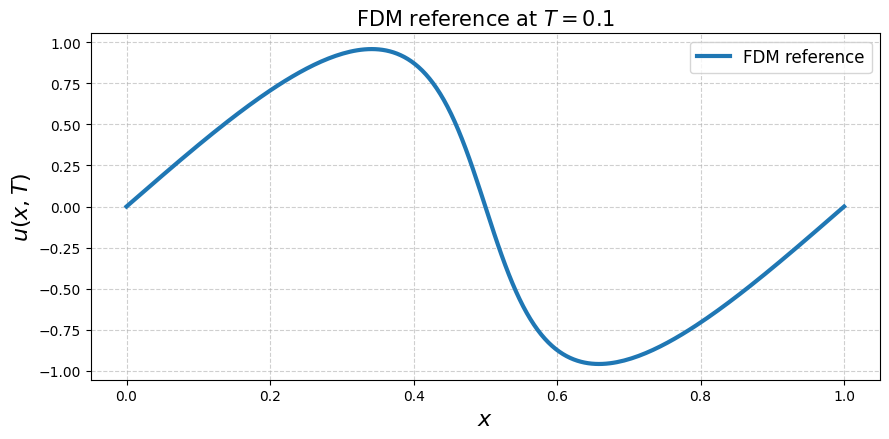

In [7]:
# %%
# ============================================================
# 7. FDM reference solution and plotting grid
# ============================================================

# Compute the finite-difference reference solution for the 1D viscous Burgers equation.
# The reference will later be used only for validation and plotting, not for training.
x_ref, t_ref, U_ref = solve_burgers_fd_periodic(
    L=L,
    Tfin=Tfin,
    nu=nu,
    Nx=Nx_ref,
    dt=dt_ref,
    convection_scheme=reference_scheme,
)

# Define a dense spatial grid for visualization of the learned solution.
x_plot = np.linspace(0.0, L, 200).reshape(-1, 1)

# Interpolate the reference solution at the final time on the plotting grid.
u_ref_final_plot, _ = reference_at_time(Tfin, t_ref, x_ref, U_ref, x_plot, L=L)

# Plot the FDM reference solution at the final time.
plt.figure(figsize=(9, 4.5))
plt.plot(x_plot.ravel(), u_ref_final_plot.ravel(), linewidth=3.0, label="FDM reference")
plt.xlabel(r"$x$", fontsize=16)
plt.ylabel(r"$u(x,T)$", fontsize=16)
plt.title(fr"FDM reference at $T={Tfin}$", fontsize=15)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()


Classical PINN trainable parameters: 521
Requested t = 0.000000; reference t used = 0.000000
MSE:         9.389410e-11
Relative L2: 1.373814e-05


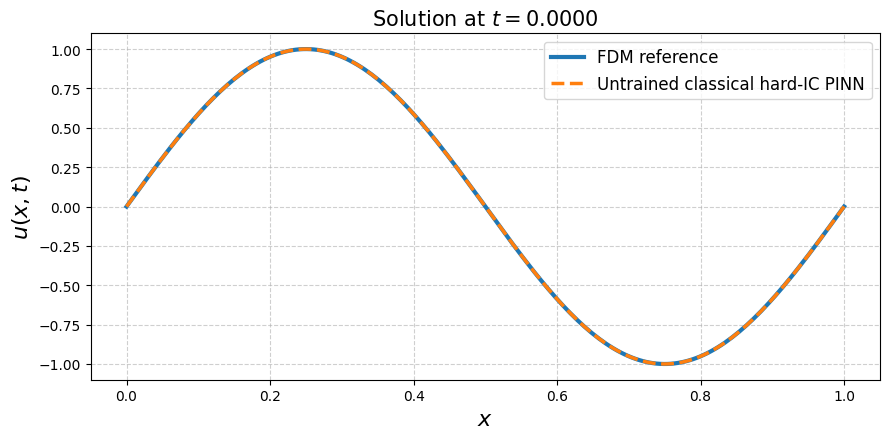


[Classical PINN] Stage 1/1 | T_stage=0.10000 | Nf=64
epoch      1/400 | loss=2.549924e+01 | r_rms=5.050e+00 | lr=2.000e-04 | time=0.0s
epoch     50/400 | loss=5.153505e+00 | r_rms=2.270e+00 | lr=2.000e-04 | time=0.1s
epoch    100/400 | loss=2.580247e+00 | r_rms=1.606e+00 | lr=2.000e-04 | time=0.1s
epoch    150/400 | loss=1.735796e+00 | r_rms=1.317e+00 | lr=2.000e-04 | time=0.2s
epoch    200/400 | loss=1.215269e+00 | r_rms=1.102e+00 | lr=2.000e-04 | time=0.2s
epoch    250/400 | loss=9.644291e-01 | r_rms=9.821e-01 | lr=2.000e-04 | time=0.3s
epoch    300/400 | loss=7.824719e-01 | r_rms=8.846e-01 | lr=2.000e-04 | time=0.3s
epoch    350/400 | loss=6.284680e-01 | r_rms=7.928e-01 | lr=2.000e-04 | time=0.4s
epoch    400/400 | loss=5.032272e-01 | r_rms=7.094e-01 | lr=2.000e-04 | time=0.5s


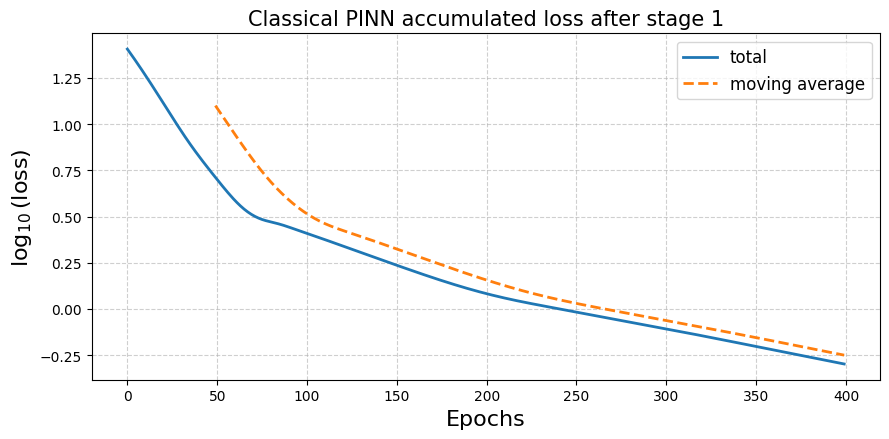

Requested t = 0.100000; reference t used = 0.100000
MSE:         4.264867e-03
Relative L2: 9.704063e-02


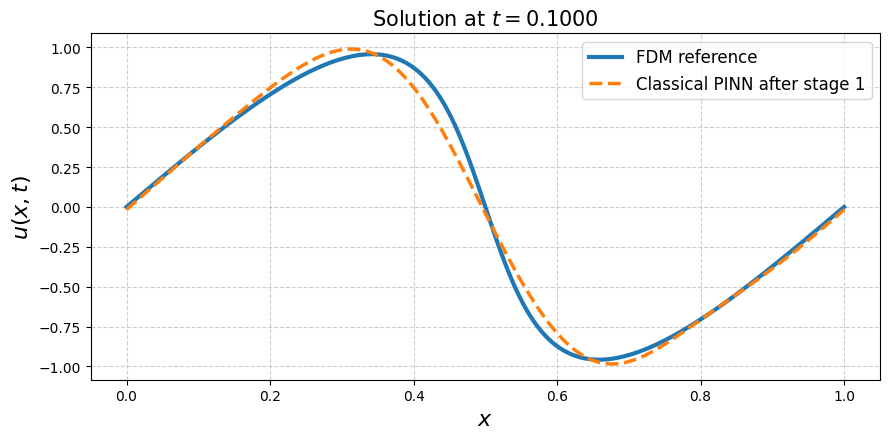

Requested t = 0.100000; reference t used = 0.100000
MSE:         4.264867e-03
Relative L2: 9.704063e-02


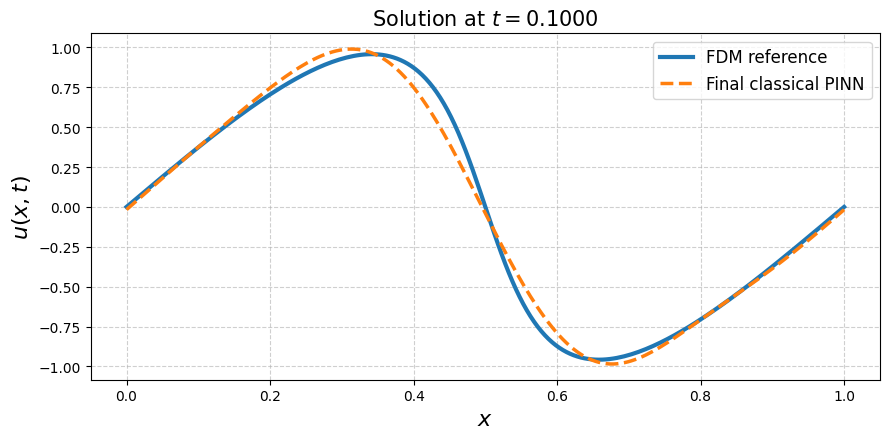

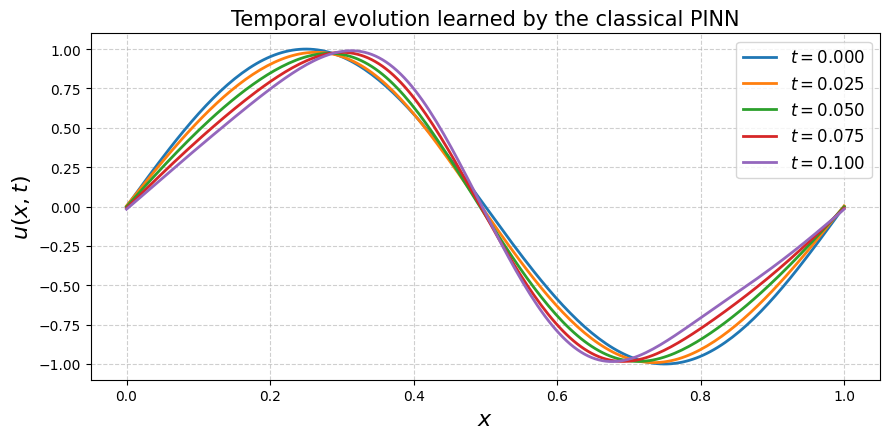

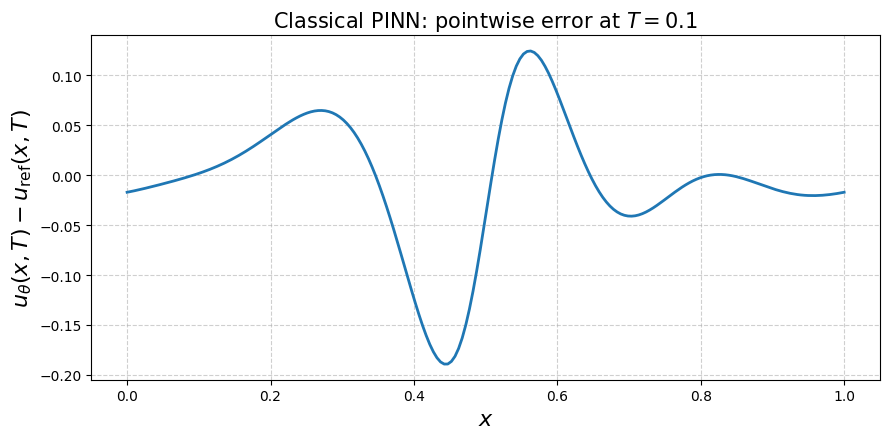

In [8]:
# %%
# ============================================================
# 8. Classical hard-IC/periodic PINN
# ============================================================

class PINN_Classical_FDResidual(nn.Module):
    """
    Classical PINN with:
      - hard initial condition: exact enforcement of u(x,0)=u0(x);
      - exact spatial periodicity through trigonometric input features;
      - Burgers residual evaluated outside the model using centered finite differences.

    The model represents the solution as

        u_theta(x,t) = u0(x) + tau * N_theta(sin(2*pi*x/L), cos(2*pi*x/L), tau),

    where tau = t/Tfin. Therefore, when t=0, tau=0 and the output is exactly u0(x).
    """

    def __init__(
        self,
        hidden_neurons=20,
        hidden_depth=3,
        activation=nn.Tanh(),
        L=1.0,
        Tfin=0.1,
    ):
        super().__init__()

        # Store the physical domain length and final time.
        self.L = float(L)
        self.Tfin = float(Tfin)

        # Build a fully classical feed-forward neural network.
        # The input dimension is 3 because the raw coordinates (x,t) are mapped to
        # three periodic/time-normalized features: sin(2*pi*x/L), cos(2*pi*x/L), tau.
        layers = [nn.Linear(3, hidden_neurons), activation]

        # Add the requested number of hidden layers.
        for _ in range(hidden_depth - 1):
            layers += [nn.Linear(hidden_neurons, hidden_neurons), activation]

        # Final linear layer maps the hidden representation to a scalar correction.
        layers += [nn.Linear(hidden_neurons, 1)]

        self.net = nn.Sequential(*layers)

    def u0(self, x):
        # Initial condition used in the hard-constraint ansatz.
        return initial_condition_torch(x, L=self.L)

    def forward(self, xt):
        # Ensure the input tensor has the same dtype as the network parameters.
        xt = xt.to(dtype=next(self.parameters()).dtype)

        # Split the input coordinates into space and time.
        x = xt[:, 0:1]
        tt = xt[:, 1:2]

        # Dimensionless time. This factor enforces the hard initial condition.
        tau = tt / self.Tfin

        # Periodic feature map in x and normalized time feature.
        # Using sin and cos guarantees exact periodicity with period L.
        features = tc.cat(
            [
                tc.sin(2.0 * math.pi * x / self.L),
                tc.cos(2.0 * math.pi * x / self.L),
                tau,
            ],
            dim=1,
        )

        # Raw neural-network correction to the initial condition.
        raw = self.net(features)

        # Hard-IC ansatz: at t=0, tau=0, hence u_theta(x,0)=u0(x) exactly.
        return self.u0(x) + tau * raw



# %%
# ============================================================
# 9. Classical PINN construction, training, and evaluation
# ============================================================

if RUN_CLASSICAL_PINN:
    # ============================================================

    # Reset random seeds to make initialization and collocation sampling reproducible.
    set_seed(MODEL_SEED)

    # Instantiate the classical PINN with the selected architecture and physical parameters.
    pinn_model = PINN_Classical_FDResidual(
        hidden_neurons=HIDDEN_NEURONS,
        hidden_depth=HIDDEN_DEPTH,
        activation=nn.Tanh(),
        L=L,
        Tfin=Tfin,
    ).to(DEVICE)

    # Deterministically initialize all linear layers and enable all trainable parameters.
    reset_linear_layers(pinn_model, seed=MODEL_SEED)
    unfreeze_all(pinn_model)

    # Print the number of trainable parameters in the classical PINN.
    print("Classical PINN trainable parameters:", count_trainable_params(pinn_model))

    # Sanity check for the hard initial condition.
    # Even before training, the model must reproduce u0(x) exactly at t=0.
    plot_solution_at_time(
        pinn_model,
        t_eval=0.0,
        x_plot=x_plot,
        t_ref=t_ref,
        x_ref=x_ref,
        U_ref=U_ref,
        L=L,
        label="Untrained classical hard-IC PINN",
    )

    # Containers for the accumulated training history and model checkpoints.
    hist_pinn_all = {"total": [], "pde": [], "lr": [], "residual_rms": [], "stage": []}
    pinn_checkpoints = {}

    # Loop over temporal curriculum stages.
    # In the current configuration, this loop has only one stage: T_stage = Tfin.
    for istage, T_stage in enumerate(T_STAGES, start=1):

        # Sample collocation points in the temporal interior of [0, T_stage].
        # The interior restriction is required because centered time differences use t +/- HT.
        x_f, t_f = sample_collocation_points(
            n_points=N_COLLOCATION_CLASSICAL,
            L=L,
            T_stage=T_stage,
            ht=HT,
            dtype=DTYPE,
            device=DEVICE,
            seed=COLLOCATION_SEED + istage,
        )

        print(f"\n[Classical PINN] Stage {istage}/{len(T_STAGES)} | T_stage={T_stage:.5f} | Nf={N_COLLOCATION_CLASSICAL}")

        # Train the PINN by minimizing the Burgers PDE residual approximated by centered differences.
        # No supervised data term is used here; the FDM solution is only used for comparison.
        pinn_model, hist_stage = train_fd_residual_stage(
            model=pinn_model,
            x_f=x_f,
            t_f=t_f,
            loss_kwargs=dict(
                L=L,
                Tfin=Tfin,
                nu=nu,
                hx=HX,
                ht=HT,
            ),
            epochs=EPOCHS_PER_STAGE_CLASSICAL,
            lr=LR_ADAM,
            grad_clip=GRAD_CLIP,
            weight_decay=WEIGHT_DECAY,
            print_every=PRINT_EVERY_CLASSICAL,
            use_scheduler=True,
            scheduler_patience=250,
            scheduler_factor=0.5,
            min_lr=1.0e-6,
        )

        # Accumulate the stage history and store a checkpoint of the trained model state.
        hist_pinn_all = append_history(hist_pinn_all, hist_stage, stage_name=f"T={T_stage:.5f}")
        pinn_checkpoints[f"stage_{istage}"] = copy_state(pinn_model)

        # Plot the accumulated training loss after this stage.
        plot_loss(
            hist_pinn_all,
            title=f"Classical PINN accumulated loss after stage {istage}",
            smooth_window=50,
        )

        # Compare the trained PINN with the FDM reference at the end of the current stage.
        plot_solution_at_time(
            pinn_model,
            t_eval=T_stage,
            x_plot=x_plot,
            t_ref=t_ref,
            x_ref=x_ref,
            U_ref=U_ref,
            L=L,
            label=f"Classical PINN after stage {istage}",
        )



    # ============================================================

    # Evaluate the final trained PINN at Tfin and compare it with the FDM reference.
    u_pinn_final, u_ref_final = plot_solution_at_time(
        pinn_model,
        t_eval=Tfin,
        x_plot=x_plot,
        t_ref=t_ref,
        x_ref=x_ref,
        U_ref=U_ref,
        L=L,
        label="Final classical PINN",
        return_data=True,
    )

    # Plot the temporal evolution learned by the classical PINN at representative times.
    plot_temporal_evolution(
        pinn_model,
        x_plot=x_plot,
        times_to_plot=[0.0, 0.25 * Tfin, 0.5 * Tfin, 0.75 * Tfin, Tfin],
        title="Temporal evolution learned by the classical PINN",
    )

    # Plot the pointwise error at final time against the FDM reference.
    plot_pointwise_error(
        x_plot=x_plot,
        u_pred=u_pinn_final,
        u_ref=u_ref_final,
        Tfin=Tfin,
        title_prefix="Classical PINN",
    )

else:
    print("Classical PINN training skipped because RUN_CLASSICAL_PINN=False.")


Available fixed quantum layers:
  - linear_cnot: Nearest-neighbor CNOT cascade: 0->1->2->... .
  - reverse_linear_cnot: Reverse nearest-neighbor CNOT cascade: ...->2->1->0 .
  - ring_cnot: Circular CNOT entangler with a closing edge from the last qubit to qubit 0.
  - brickwork_cnot: Even-odd nearest-neighbor CNOT brickwork layer, common in hardware-efficient circuits.
  - symmetric_cnot_ladder: Forward CNOT ladder followed by a reverse ladder for bidirectional correlations.
  - cz_ring: Controlled-Z graph/ring layer, equivalent to a fixed Ising-type entangling graph up to basis choices.
  - ghz_fanout: Star/fanout CNOT layer from qubit 0 to all other qubits, related to GHZ-state preparation.
  - swap_network: Nearest-neighbor SWAP network, a fixed connectivity/permutation layer used on line hardware.

Selected fixed layer: cz_ring

Fixed-gate Qiskit HPINN trainable parameters: 166
Trainable parameters inside the quantum connector: 0
Requested t = 0.000000; reference t used = 0.000000


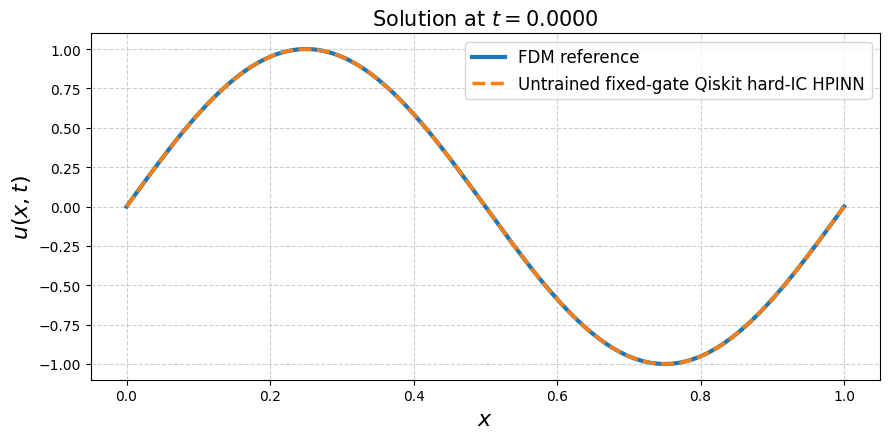


[Fixed-gate Qiskit HPINN] Stage 1/1 | T_stage=0.10000 | Nf=64
epoch      1/400 | loss=3.739583e+01 | r_rms=6.115e+00 | lr=2.000e-04 | time=3.5s
epoch     50/400 | loss=1.212596e+01 | r_rms=3.482e+00 | lr=2.000e-04 | time=172.4s
epoch    100/400 | loss=3.797444e+00 | r_rms=1.949e+00 | lr=2.000e-04 | time=346.4s
epoch    150/400 | loss=1.454824e+00 | r_rms=1.206e+00 | lr=2.000e-04 | time=520.0s
epoch    200/400 | loss=7.380705e-01 | r_rms=8.591e-01 | lr=2.000e-04 | time=692.3s
epoch    250/400 | loss=3.947460e-01 | r_rms=6.283e-01 | lr=2.000e-04 | time=863.4s
epoch    300/400 | loss=1.563200e-01 | r_rms=3.954e-01 | lr=2.000e-04 | time=1037.2s
epoch    350/400 | loss=7.778256e-02 | r_rms=2.789e-01 | lr=2.000e-04 | time=1212.2s
epoch    400/400 | loss=5.278944e-02 | r_rms=2.298e-01 | lr=2.000e-04 | time=1385.9s


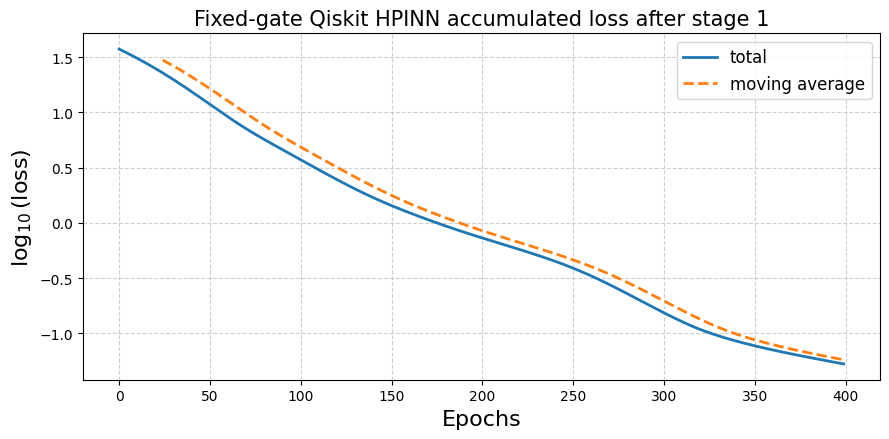

Requested t = 0.100000; reference t used = 0.100000
MSE:         3.917525e-04
Relative L2: 2.941079e-02


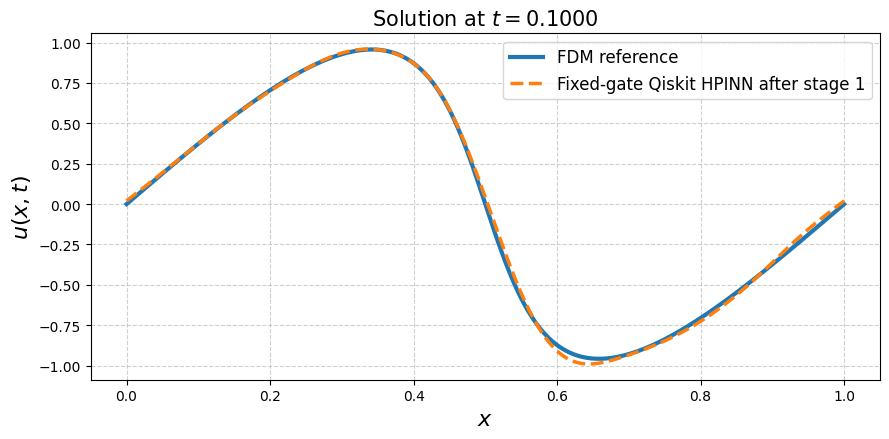

Requested t = 0.100000; reference t used = 0.100000
MSE:         3.917525e-04
Relative L2: 2.941079e-02


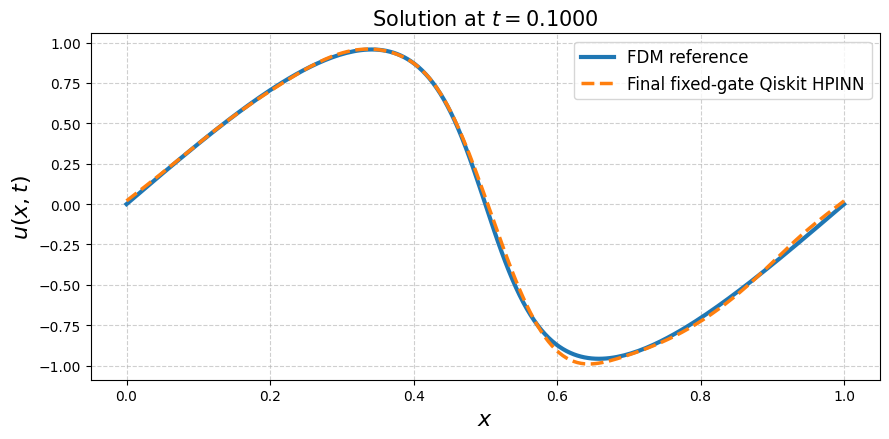

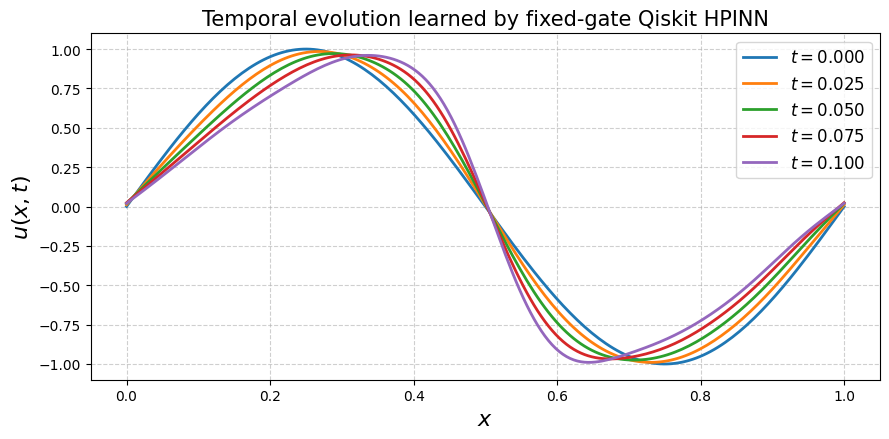

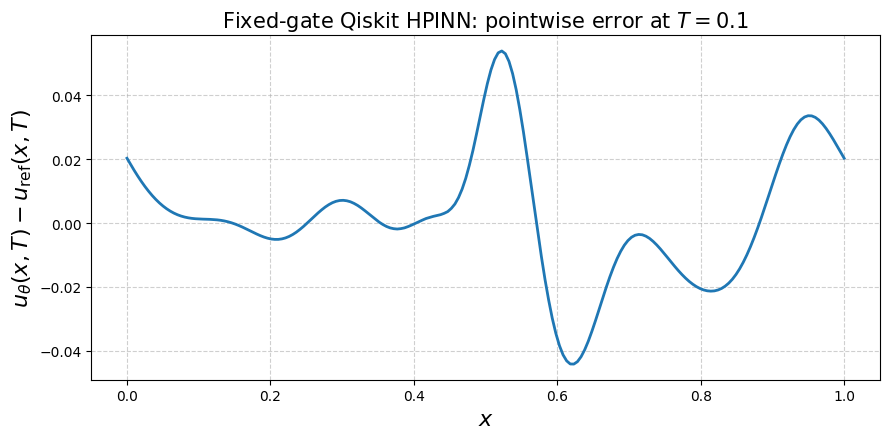

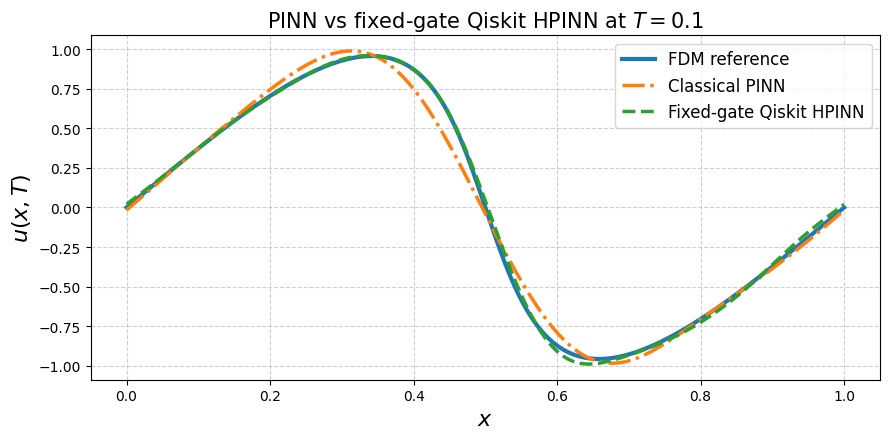

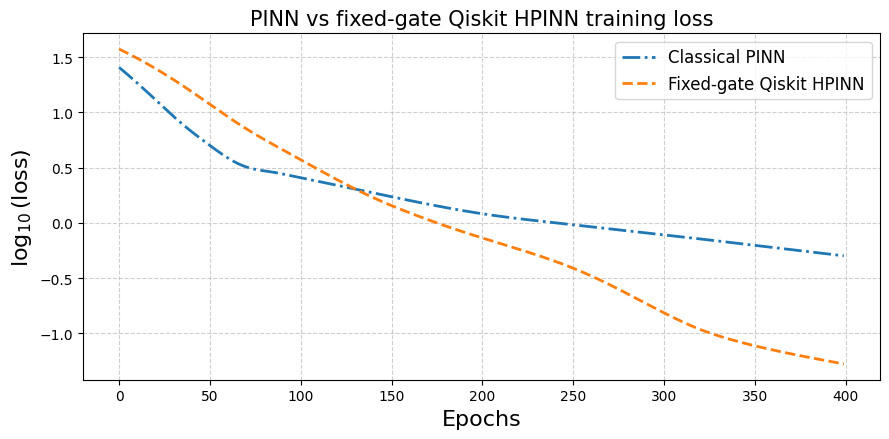

Final-time errors against the FDM reference:
  Classical PINN               | relative L2 = 4.264867e-03 | Linf = 9.704063e-02
  Fixed-gate Qiskit HPINN      | relative L2 = 3.917525e-04 | Linf = 2.941079e-02


In [9]:
# %%
# ============================================================
# 10. Fixed-gate Qiskit HPINN
# ============================================================

# The hybrid model has the structure
# periodic features -> classical pre-network -> bounded rotation angles -> fixed quantum circuit
# -> expectation values -> classical post-network -> scalar Burgers solution correction.
if RUN_QISKIT_HPINN:
    # Qiskit backend: EstimatorQNN wrapped by TorchConnector.
    from qiskit import QuantumCircuit
    from qiskit.circuit import ParameterVector

    try:
        from qiskit.primitives import StatevectorEstimator
    except ImportError:
        # Older Qiskit versions expose only Estimator. The rest of the code keeps the same interface.
        from qiskit.primitives import Estimator as StatevectorEstimator

    from qiskit.quantum_info import SparsePauliOp
    from qiskit_machine_learning.neural_networks import EstimatorQNN
    from qiskit_machine_learning.connectors import TorchConnector
    from qiskit_algorithms.gradients import ParamShiftEstimatorGradient

    # Fixed layers commonly used as entangling templates in hardware-efficient and graph-inspired circuits.
    # These are not variational ansatz layers here: they contain no trainable angles.
    FIXED_QUANTUM_LAYER_OPTIONS = {
        "linear_cnot": "Nearest-neighbor CNOT cascade: 0->1->2->... .",
        "reverse_linear_cnot": "Reverse nearest-neighbor CNOT cascade: ...->2->1->0 .",
        "ring_cnot": "Circular CNOT entangler with a closing edge from the last qubit to qubit 0.",
        "brickwork_cnot": "Even-odd nearest-neighbor CNOT brickwork layer, common in hardware-efficient circuits.",
        "symmetric_cnot_ladder": "Forward CNOT ladder followed by a reverse ladder for bidirectional correlations.",
        "cz_ring": "Controlled-Z graph/ring layer, equivalent to a fixed Ising-type entangling graph up to basis choices.",
        "ghz_fanout": "Star/fanout CNOT layer from qubit 0 to all other qubits, related to GHZ-state preparation.",
        "swap_network": "Nearest-neighbor SWAP network, a fixed connectivity/permutation layer used on line hardware.",
    }

    print("Available fixed quantum layers:")
    for layer_name, layer_description in FIXED_QUANTUM_LAYER_OPTIONS.items():
        print(f"  - {layer_name}: {layer_description}")
    print(f"\nSelected fixed layer: {FIXED_QUANTUM_LAYER}\n")

    # Build one Pauli-Z observable per qubit, so the QNN output is [<Z_0>, ..., <Z_{n-1}>].
    def qiskit_single_qubit_z_observables(n_qubits: int):
        observables = []
        for q in range(n_qubits):
            pauli = "I" * (n_qubits - q - 1) + "Z" + "I" * q
            observables.append(SparsePauliOp.from_list([(pauli, 1.0)]))
        return observables


    # Apply the data-dependent rotation embedding.
    # The rotation angles are inputs from the pre-classical network, not quantum trainable parameters.
    def qiskit_apply_input_rotations(qc: QuantumCircuit, input_params, axis: str):
        axis = axis.lower()
        for q, param in enumerate(input_params):
            if axis == "rx":
                qc.rx(param, q)
            elif axis == "ry":
                qc.ry(param, q)
            elif axis == "rz":
                qc.rz(param, q)
            else:
                raise ValueError("INPUT_ROTATION_AXIS must be one of: 'rx', 'ry', 'rz'.")


    # Apply one fixed, parameter-free entangling layer.
    def qiskit_apply_fixed_gate_layer(qc: QuantumCircuit, layer_kind: str):
        n_qubits = qc.num_qubits
        if n_qubits < 2:
            return

        layer_kind = layer_kind.lower()

        if layer_kind == "linear_cnot":
            for control in range(n_qubits - 1):
                qc.cx(control, control + 1)

        elif layer_kind == "reverse_linear_cnot":
            for control in range(n_qubits - 1, 0, -1):
                qc.cx(control, control - 1)

        elif layer_kind == "ring_cnot":
            for control in range(n_qubits - 1):
                qc.cx(control, control + 1)
            if n_qubits > 2:
                qc.cx(n_qubits - 1, 0)

        elif layer_kind == "brickwork_cnot":
            for control in range(0, n_qubits - 1, 2):
                qc.cx(control, control + 1)
            for control in range(1, n_qubits - 1, 2):
                qc.cx(control, control + 1)

        elif layer_kind == "symmetric_cnot_ladder":
            for control in range(n_qubits - 1):
                qc.cx(control, control + 1)
            for control in range(n_qubits - 1, 0, -1):
                qc.cx(control, control - 1)

        elif layer_kind == "cz_ring":
            for q in range(n_qubits - 1):
                qc.cz(q, q + 1)
            if n_qubits > 2:
                qc.cz(n_qubits - 1, 0)

        elif layer_kind == "ghz_fanout":
            for target in range(1, n_qubits):
                qc.cx(0, target)

        elif layer_kind == "swap_network":
            for q in range(n_qubits - 1):
                qc.swap(q, q + 1)

        else:
            options = ", ".join(FIXED_QUANTUM_LAYER_OPTIONS)
            raise ValueError(f"Unknown fixed quantum layer '{layer_kind}'. Available options: {options}.")


    # Build the full Qiskit feature circuit.
    # Only the input rotations are parameterized; all subsequent quantum gates are fixed logical gates.
    def qiskit_build_fixed_feature_qc(
        n_qubits: int,
        layer_kind: str,
        repeats: int = 1,
        input_rotation_axis: str = "rx",
    ):
        input_params = ParameterVector("inputs", n_qubits)
        qc = QuantumCircuit(n_qubits, name=f"fixed_{layer_kind}")

        qiskit_apply_input_rotations(qc, input_params, input_rotation_axis)

        for _ in range(repeats):
            qiskit_apply_fixed_gate_layer(qc, layer_kind)

        return qc, list(input_params)


    class HPINN_Qiskit_FixedGate_FDResidual(nn.Module):
        """
        Qiskit HPINN with:
          - hard initial condition;
          - exact periodicity through trigonometric input features;
          - a pre-classical network that generates bounded rotation angles in (-pi, pi);
          - a fixed, parameter-free quantum gate layer;
          - Burgers residual evaluated outside the model by centered finite differences.
        """

        def __init__(
            self,
            n_qubits=4,
            pre_neurons=20,
            pre_depth=1,
            post_neurons=20,
            post_depth=1,
            activation=nn.Tanh(),
            angle_scale=math.pi,
            fixed_layer="brickwork_cnot",
            fixed_layer_repeats=1,
            input_rotation_axis="rx",
            seed=42,
            L=1.0,
            Tfin=0.1,
        ):
            super().__init__()

            # Store quantum and physical configuration.
            self.n_qubits = int(n_qubits)
            self.fixed_layer = fixed_layer
            self.fixed_layer_repeats = int(fixed_layer_repeats)
            self.input_rotation_axis = input_rotation_axis
            self.angle_scale = float(angle_scale)
            self.L = float(L)
            self.Tfin = float(Tfin)

            # Classical pre-network maps periodic features (sin, cos, tau) to N_QUBITS raw values.
            pre_layers = [nn.Linear(3, pre_neurons), activation]
            for _ in range(pre_depth - 1):
                pre_layers += [nn.Linear(pre_neurons, pre_neurons), activation]
            pre_layers += [nn.Linear(pre_neurons, n_qubits)]
            self.pre = nn.Sequential(*pre_layers)

            # Build the fixed feature circuit and vector-valued observable set.
            qc, input_params = qiskit_build_fixed_feature_qc(
                n_qubits=n_qubits,
                layer_kind=fixed_layer,
                repeats=fixed_layer_repeats,
                input_rotation_axis=input_rotation_axis,
            )
            observables = qiskit_single_qubit_z_observables(n_qubits)
            self.circuit = qc

            # StatevectorEstimator gives deterministic expectation values in simulation.
            try:
                estimator = StatevectorEstimator(default_precision=0.0, seed=seed)
            except TypeError:
                estimator = StatevectorEstimator()

            # Parameter-shift gradients are used only for the input rotation angles.
            try:
                gradient = ParamShiftEstimatorGradient(estimator=estimator, precision=0.0)
            except TypeError:
                gradient = ParamShiftEstimatorGradient(estimator)

            # weight_params is empty by construction: the quantum circuit has no trainable weights.
            qnn_kwargs = dict(
                circuit=qc,
                estimator=estimator,
                observables=observables,
                input_params=input_params,
                weight_params=[],
                gradient=gradient,
                input_gradients=True,
            )

            # Keep compatibility with Qiskit versions that may not accept default_precision.
            try:
                qnn = EstimatorQNN(**qnn_kwargs, default_precision=0.0)
            except TypeError:
                qnn = EstimatorQNN(**qnn_kwargs)

            # TorchConnector makes the QNN behave as a Torch module.
            # The empty initial_weights array confirms that the quantum layer is fixed.
            self.quantum = TorchConnector(
                qnn,
                initial_weights=np.zeros(qnn.num_weights, dtype=np.float32),
            )

            # Classical post-network maps quantum expectation values to a scalar correction.
            post_layers = [nn.Linear(n_qubits, post_neurons), activation]
            for _ in range(post_depth - 1):
                post_layers += [nn.Linear(post_neurons, post_neurons), activation]
            post_layers += [nn.Linear(post_neurons, 1)]
            self.post = nn.Sequential(*post_layers)

        def u0(self, x):
            # Initial condition used in the hard-constraint ansatz.
            return initial_condition_torch(x, L=self.L)

        def forward(self, xt):
            # Ensure the input tensor has the same dtype as the classical trainable layers.
            xt = xt.to(dtype=self.pre[0].weight.dtype)

            # Split coordinates and normalize time to tau in [0, 1].
            x = xt[:, 0:1]
            tt = xt[:, 1:2]
            tau = tt / self.Tfin

            # Periodic feature map makes the ansatz exactly periodic in x.
            features = tc.cat(
                [
                    tc.sin(2.0 * math.pi * x / self.L),
                    tc.cos(2.0 * math.pi * x / self.L),
                    tau,
                ],
                dim=1,
            )

            # The pre-network output is bounded to (-pi, pi) before becoming rotation angles.
            # These angles change during training only through the pre-classical parameters.
            raw_angles = self.pre(features)
            rotation_angles = self.angle_scale * tc.tanh(raw_angles)

            # Fixed quantum feature layer followed by a classical post-network.
            q = self.quantum(rotation_angles)
            q = q.to(dtype=self.post[0].weight.dtype)
            raw = self.post(q)

            # Hard initial condition: at t=0, tau=0 and the output is exactly u0(x).
            return self.u0(x) + tau * raw

        def show_circuit(self):
            # Return a Matplotlib drawing of the selected fixed Qiskit circuit.
            return self.circuit.draw("mpl")


    # Reset random seeds to make initialization and collocation sampling reproducible.
    set_seed(MODEL_SEED)

    # Instantiate the fixed-gate Qiskit HPINN with the selected architecture and layer template.
    hpinn_qiskit = HPINN_Qiskit_FixedGate_FDResidual(
        n_qubits=N_QUBITS,
        pre_neurons=PRE_NEURONS,
        pre_depth=PRE_DEPTH,
        post_neurons=POST_NEURONS,
        post_depth=POST_DEPTH,
        activation=nn.Tanh(),
        angle_scale=PRE_ANGLE_SCALE,
        fixed_layer=FIXED_QUANTUM_LAYER,
        fixed_layer_repeats=FIXED_LAYER_REPEATS,
        input_rotation_axis=INPUT_ROTATION_AXIS,
        seed=MODEL_SEED,
        L=L,
        Tfin=Tfin,
    ).to(DEVICE)

    # Deterministically initialize all classical linear layers and enable trainable classical parameters.
    reset_linear_layers(hpinn_qiskit, seed=MODEL_SEED)
    unfreeze_all(hpinn_qiskit)

    # Report the parameter count. The quantum parameter count should be zero.
    quantum_trainable_params = sum(p.numel() for p in hpinn_qiskit.quantum.parameters() if p.requires_grad)
    print("Fixed-gate Qiskit HPINN trainable parameters:", count_trainable_params(hpinn_qiskit))
    print("Trainable parameters inside the quantum connector:", quantum_trainable_params)

    # Sanity check for the hard initial condition.
    plot_solution_at_time(
        hpinn_qiskit,
        t_eval=0.0,
        x_plot=x_plot,
        t_ref=t_ref,
        x_ref=x_ref,
        U_ref=U_ref,
        L=L,
        label="Untrained fixed-gate Qiskit hard-IC HPINN",
    )

    # Containers for accumulated Qiskit diagnostics and model checkpoints.
    hist_qiskit_all = {"total": [], "pde": [], "lr": [], "residual_rms": [], "stage": []}
    qiskit_checkpoints = {}

    # Curriculum loop: sample collocation points and train on each time window.
    for istage, T_stage in enumerate(T_STAGES, start=1):
        x_f, t_f = sample_collocation_points(
            n_points=N_COLLOCATION_QISKIT,
            L=L,
            T_stage=T_stage,
            ht=HT,
            dtype=DTYPE,
            device=DEVICE,
            seed=COLLOCATION_SEED + istage,
        )

        print(f"\n[Fixed-gate Qiskit HPINN] Stage {istage}/{len(T_STAGES)} | T_stage={T_stage:.5f} | Nf={N_COLLOCATION_QISKIT}")

        # Train the hybrid model by minimizing the same discretized Burgers PDE residual.
        hpinn_qiskit, hist_stage = train_fd_residual_stage(
            model=hpinn_qiskit,
            x_f=x_f,
            t_f=t_f,
            loss_kwargs=dict(
                L=L,
                Tfin=Tfin,
                nu=nu,
                hx=HX,
                ht=HT,
            ),
            epochs=EPOCHS_PER_STAGE_QISKIT,
            lr=LR_ADAM,
            grad_clip=GRAD_CLIP,
            weight_decay=WEIGHT_DECAY,
            print_every=PRINT_EVERY_QISKIT,
            use_scheduler=True,
            scheduler_patience=100,
            scheduler_factor=0.5,
            min_lr=1.0e-6,
        )

        # Accumulate diagnostics and save the current state after each stage.
        hist_qiskit_all = append_history(hist_qiskit_all, hist_stage, stage_name=f"T={T_stage:.5f}")
        qiskit_checkpoints[f"stage_{istage}"] = copy_state(hpinn_qiskit)

        # Plot the accumulated loss and the solution at the end of the current stage.
        plot_loss(
            hist_qiskit_all,
            title=f"Fixed-gate Qiskit HPINN accumulated loss after stage {istage}",
            smooth_window=25,
        )
        plot_solution_at_time(
            hpinn_qiskit,
            t_eval=T_stage,
            x_plot=x_plot,
            t_ref=t_ref,
            x_ref=x_ref,
            U_ref=U_ref,
            L=L,
            label=f"Fixed-gate Qiskit HPINN after stage {istage}",
        )

    # Evaluate the final trained hybrid model at Tfin.
    u_qiskit_final, u_ref_final_qiskit = plot_solution_at_time(
        hpinn_qiskit,
        t_eval=Tfin,
        x_plot=x_plot,
        t_ref=t_ref,
        x_ref=x_ref,
        U_ref=U_ref,
        L=L,
        label="Final fixed-gate Qiskit HPINN",
        return_data=True,
    )

    # Plot the temporal evolution learned by the fixed-gate hybrid model.
    plot_temporal_evolution(
        hpinn_qiskit,
        x_plot=x_plot,
        times_to_plot=[0.0, 0.25 * Tfin, 0.5 * Tfin, 0.75 * Tfin, Tfin],
        title="Temporal evolution learned by fixed-gate Qiskit HPINN",
    )

    # Plot the pointwise error at final time against the FDM reference.
    plot_pointwise_error(
        x_plot=x_plot,
        u_pred=u_qiskit_final,
        u_ref=u_ref_final_qiskit,
        Tfin=Tfin,
        title_prefix="Fixed-gate Qiskit HPINN",
    )

# %%
# ============================================================
# 11. Final comparison: Classical PINN vs fixed-gate Qiskit HPINN
# ============================================================

# This block compares only the models that were actually trained in the current notebook session.
predictions = []
histories = []
error_rows = []

# Use the reference already computed on x_plot.
u_ref_compare = u_ref_final_plot

if "u_pinn_final" in globals():
    predictions.append(("Classical PINN", u_pinn_final, "-."))
    histories.append(("Classical PINN", hist_pinn_all, "-."))
    l2_rel, linf = compute_errors(u_pinn_final, u_ref_compare)
    error_rows.append(("Classical PINN", l2_rel, linf))

if "u_qiskit_final" in globals():
    predictions.append(("Fixed-gate Qiskit HPINN", u_qiskit_final, "--"))
    histories.append(("Fixed-gate Qiskit HPINN", hist_qiskit_all, "--"))
    l2_rel, linf = compute_errors(u_qiskit_final, u_ref_compare)
    error_rows.append(("Fixed-gate Qiskit HPINN", l2_rel, linf))

if len(predictions) > 0:
    # Final solution comparison against the FDM reference.
    plt.figure(figsize=(9, 4.5))
    plt.plot(x_plot.ravel(), u_ref_compare.ravel(), linewidth=3.0, label="FDM reference")
    for label, u_pred, style in predictions:
        plt.plot(x_plot.ravel(), u_pred.ravel(), style, linewidth=2.5, label=label)
    plt.xlabel(r"$x$", fontsize=16)
    plt.ylabel(r"$u(x,T)$", fontsize=16)
    plt.title(fr"PINN vs fixed-gate Qiskit HPINN at $T={Tfin}$", fontsize=15)
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.legend(fontsize=12)
    plt.tight_layout()
    plt.show()

    # Training-loss comparison.
    plt.figure(figsize=(9, 4.5))
    for label, hist, style in histories:
        plt.plot(
            np.log10(np.asarray(hist["total"]) + 1.0e-16),
            style,
            linewidth=2.0,
            label=label,
        )
    plt.xlabel("Epochs", fontsize=16)
    plt.ylabel(r"$\log_{10}(\mathrm{loss})$", fontsize=16)
    plt.title("PINN vs fixed-gate Qiskit HPINN training loss", fontsize=15)
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.legend(fontsize=12)
    plt.tight_layout()
    plt.show()

    # Print numerical error metrics at final time.
    print("Final-time errors against the FDM reference:")
    for label, l2_rel, linf in error_rows:
        print(f"  {label:28s} | relative L2 = {l2_rel:.6e} | Linf = {linf:.6e}")
else:
    print("No trained model outputs were found for comparison.")

